### Student Name: Asangika Hettiarachchi
### ID: 7461502


# Project Introduction: Iris Flower Classification Using Logistic Regression

## Objective
The objective of this project is to evaluate the performance of a Logistic Regression model using the Iris flower dataset from the `sklearn` library. Cross-validation is used to measure the model's classification accuracy and consistency across multiple data splits.

## Dataset Description
The Iris dataset contains 150 flower samples belonging to three species: Setosa, Versicolor, and Virginica. Each sample includes four numerical features:

- Sepal length
- Sepal width
- Petal length
- Petal width

The target variable represents the species of each iris flower.

## Methodology
The following steps are performed in this project:

1. Load the Iris dataset using `sklearn.datasets`.
2. Separate the dataset into features (X) and target labels (y).
3. Create a Logistic Regression classification model.
4. Apply five-fold cross-validation using `cross_val_score()`.
5. Calculate and analyze the accuracy scores for each fold.
6. Evaluate the model using the mean accuracy and standard deviation.

## Expected Outcome
This analysis will provide an estimate of how accurately Logistic Regression classifies iris flower species and how consistently the model performs across different validation folds.


In [1]:

# Import the required libraries

from sklearn.datasets import load_iris
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

import numpy as np
import pandas as pd



## 1. Load the Data Set

The Iris dataset is a built-in dataset available in Scikit-learn. It contains 150 flower samples belonging to three species: Setosa, Versicolor, and Virginica.

Each sample has four numerical features: sepal length, sepal width, petal length, and petal width.

In this section, we load the dataset and separate the input features (X) from the target labels (y).


In [2]:

# Load the Iris dataset
iris= load_iris()

# Separate features and target labels
X = iris.data
y = iris.target

# Create a DataFrame
iris_df = pd.DataFrame(X, columns=iris.feature_names)
iris_df["species"] = iris.target_names[y]

# Display basic information
print("Dataset loaded successfully!")
print("Dataset shape:", iris_df.shape)
display(iris_df.head())

print("Feature names:", iris.feature_names)
print("Target names:", iris.target_names)


Dataset loaded successfully!
Dataset shape: (150, 5)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


Feature names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Target names: ['setosa' 'versicolor' 'virginica']



## 2. Exploratory Data Analysis (EDA)

Exploratory Data Analysis (EDA) helps us understand the dataset before training the model. In this section, we examine the dataset's dimensions, column names, data types, missing values, species distribution, and descriptive statistics.


In [3]:

# Explore the Iris dataset

print("Dataset Shape:", iris_df.shape)

print("\nDataset Information:")
iris_df.info()

print("\nFirst Five Rows:")
display(iris_df.head())

print("\nMissing Values:")
print(iris_df.isnull().sum())

print("\nSpecies Distribution:")
print(iris_df["species"].value_counts())

print("\nDescriptive Statistics:")
display(iris_df.describe())


Dataset Shape: (150, 5)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB

First Five Rows:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa



Missing Values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64

Species Distribution:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

Descriptive Statistics:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


### 3.Logistic Regression Model

Logistic Regression is a supervised machine learning algorithm used for classification. In this project, it will classify iris flowers into Setosa, Versicolor, and Virginica based on their four numerical measurements.

We will evaluate the model using five-fold cross-validation to measure its accuracy across different subsets of the dataset.


In [4]:

# Create the Logistic Regression model
model = LogisticRegression(max_iter=200)

# Fit the model using the Iris dataset
model.fit(X, y)

print("Logistic Regression model created & fitted successfully.")


Logistic Regression model created & fitted successfully.


### 4.Model Evaluation Using Cross-Validation

Cross-validation is a technique used to evaluate the performance and consistency of a machine learning model. In five-fold cross-validation, the dataset is divided into five subsets (folds). The model is trained on four folds and tested on the remaining fold. This process is repeated five times, with each fold used once for testing.

The `cross_val_score()` function measures the model's accuracy for each fold. We will calculate the individual accuracy scores, mean accuracy, and standard deviation to evaluate the model's performance.


In [5]:

# Evaluate Logistic Regression using 5-fold cross-validation
scores = cross_val_score(model, X, y, cv=5, scoring="accuracy")

# Display accuracy for each fold
print("Accuracy scores for each fold:", scores)

# Calculate mean accuracy and standard deviation
mean_accuracy = np.mean(scores)
std_accuracy = np.std(scores)

print(f"\nMean accuracy: {mean_accuracy:.4f}")
print(f"Mean accuracy (%): {mean_accuracy * 100:.2f}%")
print(f"Standard deviation: {std_accuracy:.4f}")

# Display results in a DataFrame
cv_results = pd.DataFrame({
    "Fold": range(1, 6),
    "Accuracy": scores
})

display(cv_results)


Accuracy scores for each fold: [0.96666667 1.         0.93333333 0.96666667 1.        ]

Mean accuracy: 0.9733
Mean accuracy (%): 97.33%
Standard deviation: 0.0249


,Fold,Accuracy
0,1,0.966667
1,2,1.000000
2,3,0.933333
3,4,0.966667
4,5,1.000000



### Cross-Validation Observations

The Logistic Regression model was evaluated using five-fold cross-validation with accuracy as the evaluation metric.

- **Fold accuracy scores:** The model achieved accuracies of 96.67%, 100%, 93.33%, 96.67%, and 100% across the five folds.
- **Mean accuracy:** The average accuracy was 97.33%, indicating that the model correctly classified approximately 97.33% of the samples across the validation folds.
- **Standard deviation:** The standard deviation was 0.0249, indicating relatively low variation in accuracy across the five folds.

Overall, the model demonstrated high classification accuracy and consistent performance across the validation folds.



## 5. Visualization of Cross-Validation Results

A bar chart is used to visualize the accuracy scores obtained from five-fold cross-validation. Comparing the scores helps us understand the consistency of the Logistic Regression model across different validation folds.


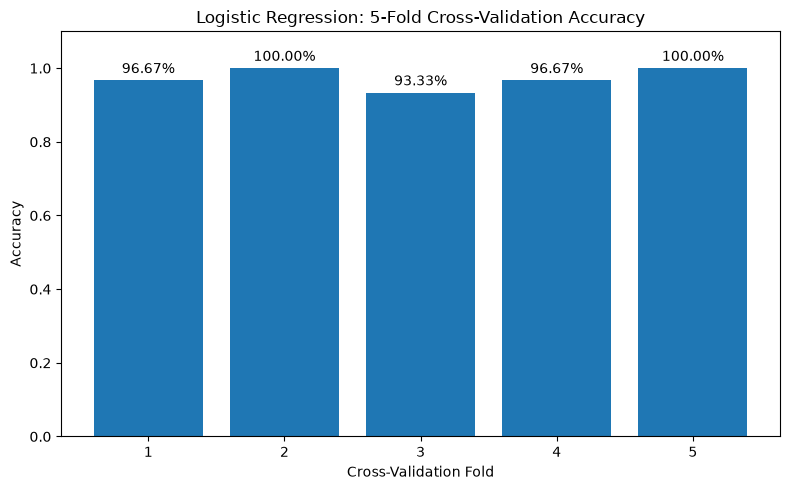

In [6]:

import matplotlib.pyplot as plt

# Plot accuracy for each fold
plt.figure(figsize=(8, 5))
plt.bar(cv_results["Fold"], cv_results["Accuracy"])

plt.title("Logistic Regression: 5-Fold Cross-Validation Accuracy")
plt.xlabel("Cross-Validation Fold")
plt.ylabel("Accuracy")
plt.xticks(cv_results["Fold"])
plt.ylim(0, 1.1)

# Add accuracy labels above each bar
for fold, accuracy in zip(cv_results["Fold"], cv_results["Accuracy"]):
    plt.text(fold, accuracy + 0.02, f"{accuracy:.2%}", ha="center")

plt.tight_layout()
plt.show()



### Visualization Observations

The bar chart shows that the accuracy scores range from 93.33% to 100% across the five folds. Two folds achieved 100% accuracy, while the remaining folds achieved accuracy above 93%.

The relatively small differences between the scores suggest that the Logistic Regression model performs consistently across different subsets of the Iris dataset.



## 6. Final Conclusion

### Summary

In this project, the Iris flower dataset from Scikit-learn was used to evaluate a Logistic Regression classification model. The dataset contains 150 samples, four numerical features, and three flower species: Setosa, Versicolor, and Virginica.

Five-fold cross-validation was performed using `cross_val_score()` with accuracy as the evaluation metric.

### Key Findings

- **Mean accuracy:** The model achieved an average accuracy of 97.33% across five folds.
- **Fold accuracy:** The individual accuracy scores ranged from 93.33% to 100%.
- **Consistency:** The standard deviation of 0.0249 indicates relatively low variation in accuracy across the folds.
- **Visualization:** The bar chart helped compare the model's performance across all five folds.

### Final Observation

The results indicate that Logistic Regression performs well on the Iris dataset, achieving high classification accuracy across different validation folds. Five-fold cross-validation provides a more reliable estimate of model performance than relying on a single train-test split.


